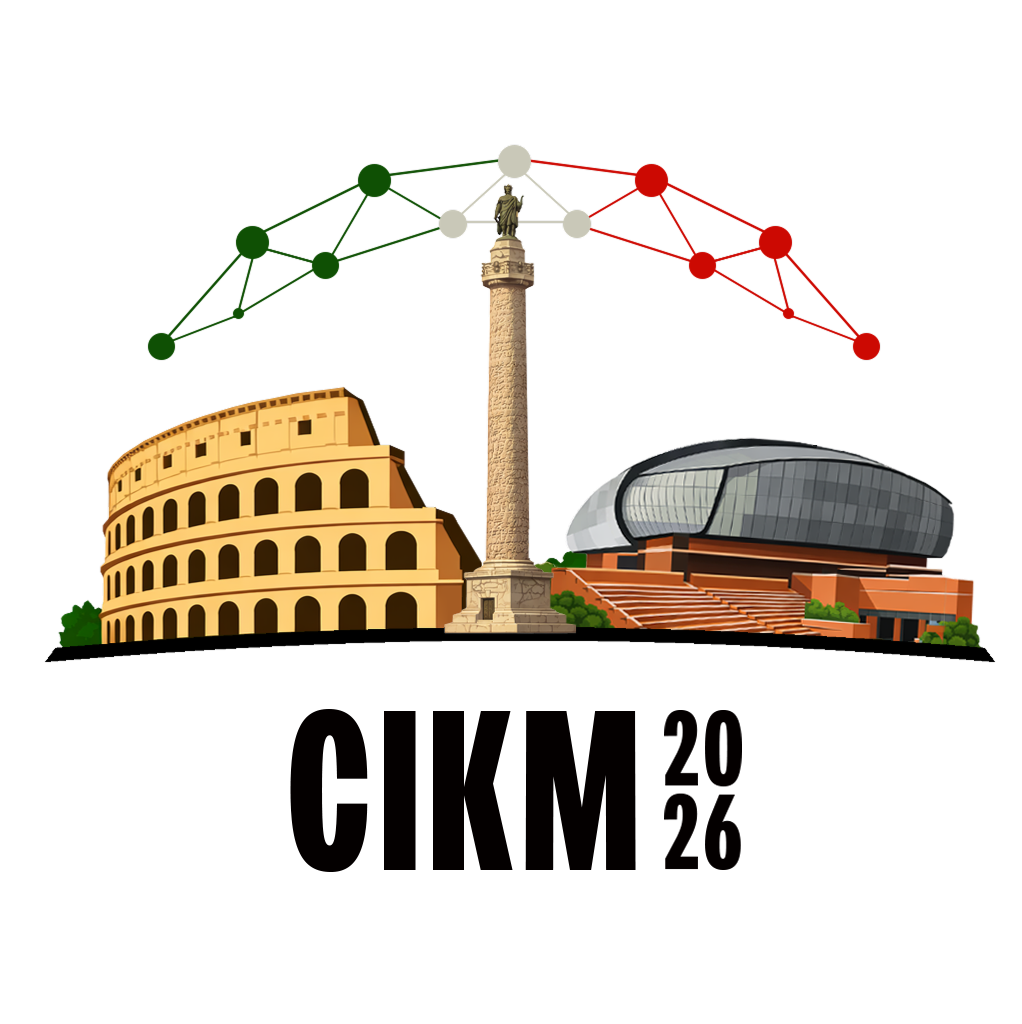

# M2: See how typos and added documents change search

Beyond Benchmarks: Robustness for Real-World Information Systems

Bum Jun Kim, The University of Tokyo, CIKM 2026

7 November 2026 · [San Pietro in Vincoli Campus, Sapienza University of Rome](https://cikm2026.diag.uniroma1.it/venues/) · Rome, Italy

Learning objective: Measure how a typo changes the query vector. Then check how an added attack document changes the ranking.


## Two changes to test

- Query Embedding Drift: add typos and measure how much the query vector changes. Keep the papers fixed.
- Document Insertion: add a document and check the ranking. Keep the query fixed.

Both tests keep the model weights fixed. [M1](M1_Observe_Failures.ipynb#m1-pipeline) explains the dataset, relevance labels (qrels), and search steps.


### Setup

Run this notebook on its own with Restart Kernel → Run All. Keep `resources/` next to the notebooks. See the [README](README.md) for setup and cache help.

The setup checks the SciFact files. The experiments read saved MiniLM vectors and rankings, including rankings after document insertion. They do not run the models again or change the supplied collection.


In [1]:
# Load the libraries, SciFact data, and saved model results.
from pathlib import Path
import sys
ROOT = next(p / "resources" for p in [Path.cwd(), *Path.cwd().parents] if (p / "resources" / "tutorial_utils").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
%matplotlib inline
from tutorial_utils import load_tutorial_context
from tutorial_utils import m2_lesson as lesson
from tutorial_utils import plotting as viz
from tutorial_utils.presentation import install_plain_display
install_plain_display()
MODE = "cached"
ctx = load_tutorial_context(mode=MODE, seed=42)
print(ctx.banner())

MODE=cached | SciFact | 5183 documents | 300 test queries
BM25 / MiniLM dense exact retrieval → MiniLM cross-encoder (20 candidates)


<a id="m2-settings"></a>
## Experiment Settings

Choose one of M1's three queries. Set `severity` to the maximum character edits, from 0 to 3. Zero leaves the query unchanged. A short query may receive fewer edits than the maximum.

Then select the code cell below and use Run All Below. `severity` affects only the typo test. The insertion test always uses the original query and one added document.


In [2]:
# Choose the query and maximum number of character edits.
query_id = "1303"           # Tirasemtiv (default); "1012": radioiodine; "628": HTLV-1.
severity = 1                # typo only; maximum character edits: 0–3

## Query Embedding Drift: How much does the vector change?

A typo can change the query vector's direction. We measure that change with 1 − cosine similarity. For original vector $e(q)$ and typo vector $e(q')$:

$$d(q,q')=1-\cos(e(q),e(q')).$$

Zero means the directions match. A larger value means they differ more. This distance does not measure search quality. Check the returned papers against qrels to see whether evidence was lost.

The output shows the edited words and vector distance.


In [3]:
# Show how a typo changes the selected query's vector.
query_demo = lesson.show_query_shift(ctx, query_id, severity)

### Compare the three queries

Each bar shows the vector distance between an original query and its typo version. All bars use the same scale. A shorter bar means less vector change. Check relevance separately.


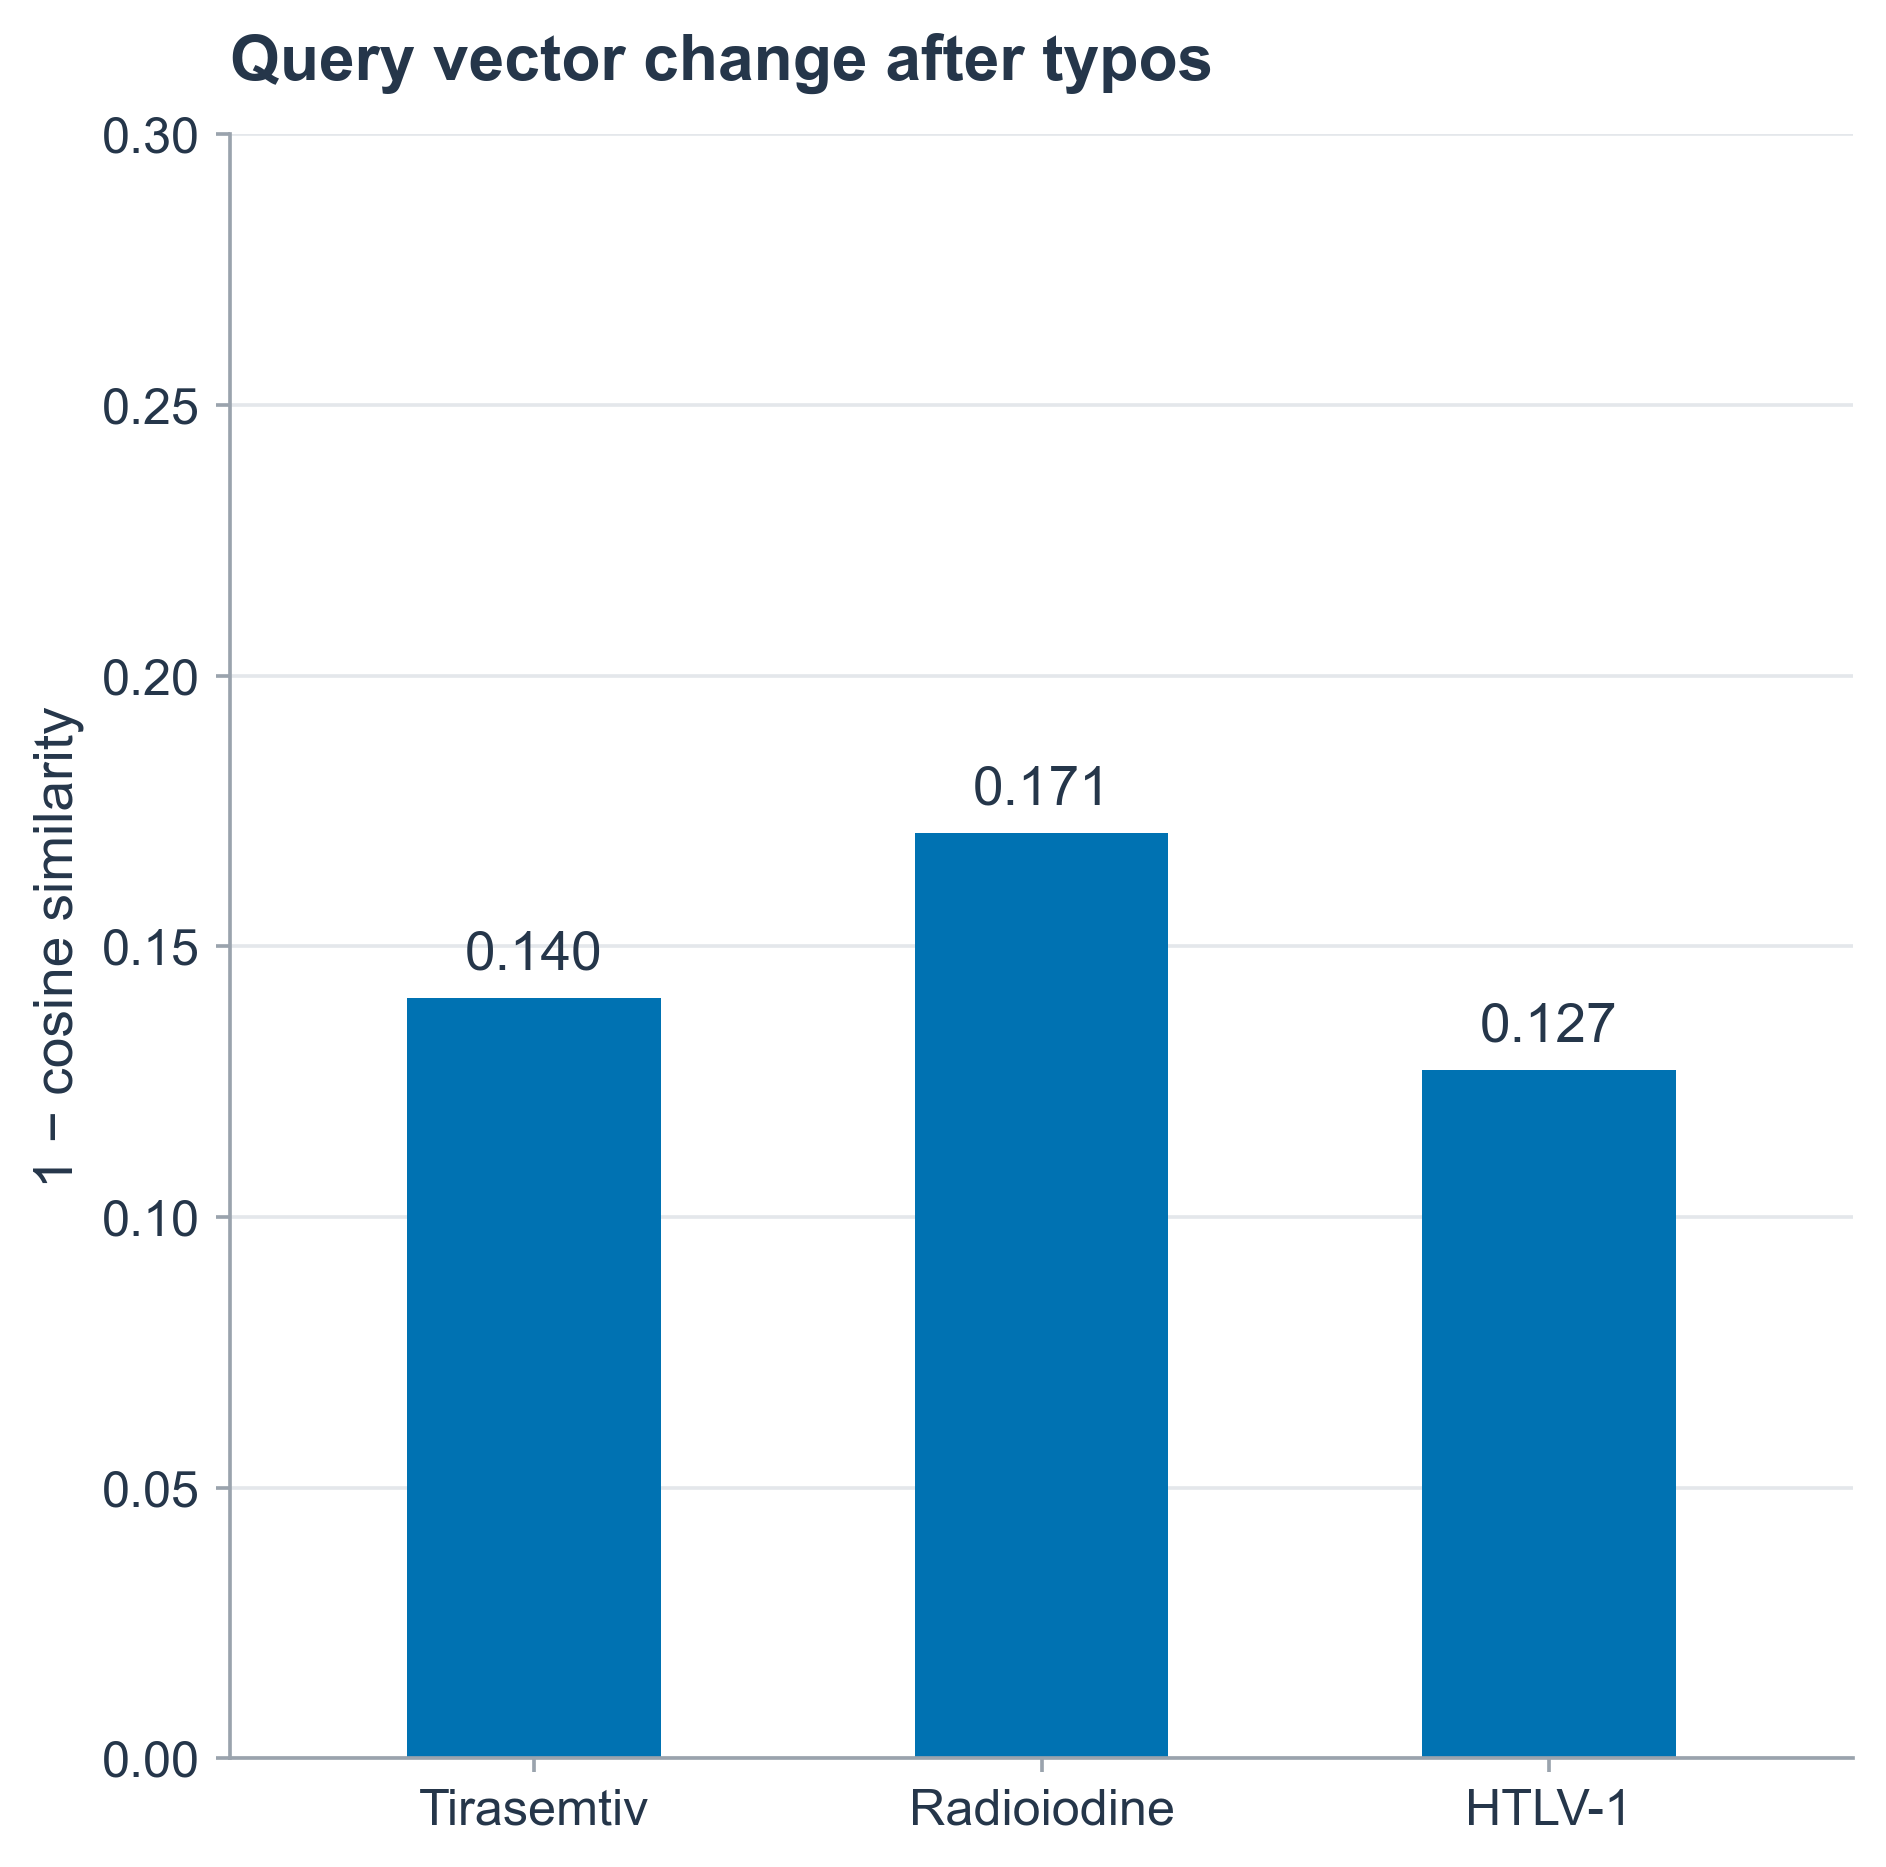

In [4]:
# Plot query vector changes for the three example queries.
viz.show(lesson.embedding_figure(ctx, query_id, severity))
lesson.show_embedding_interpretation(ctx, query_id, severity)

## Document Insertion: Can a repeated claim outrank evidence?

Add one artificial passage that repeats the claim but gives no scientific evidence. Keep the query and original papers fixed. Check where the attack ranks and which papers leave the top ten.

Attack Hit@10 is 1 when the attack appears in the top ten, and 0 otherwise. For the defender, 0 is better. Rank 1 is first. `absent` means the attack is outside the 20 candidates.

`[relevant]` marks a paper with a positive qrel. A high model score alone does not make a paper relevant.


In [5]:
# Compare paper rankings before and after inserting an attack document.
insertion_demo = lesson.show_insertion(ctx, query_id)

Stage,Corpus,Inserted rank / 20,Hit@10
Dense,Original,absent,0
Dense,After insertion,1,1
Reranker,Original,absent,0
Reranker,After insertion,1,1


Rank,Original,After insertion
1,12631697 [relevant],Inserted
2,43566999,12631697 [relevant]
3,30101891,43566999
4,34328964,30101891
5,37037012,34328964
6,23737024,37037012
7,19994006,23737024
8,33554389,19994006
9,6549091,33554389
10,23865182,6549091


Rank,Original,After insertion
1,12631697 [relevant],Inserted
2,40631095,12631697 [relevant]
3,23737024,40631095
4,34328964,23737024
5,37037012,34328964
6,1275505,37037012
7,33554389,1275505
8,32322418,33554389
9,25475802,32322418
10,29526125,25475802


### Check what happened to the evidence

Vector distance measures query change. The insertion tables show which papers moved or disappeared. To judge search quality, check the relevant papers.

Use [M1's candidate-recall check](M1_Observe_Failures.ipynb#m1-candidate-check): did search find the evidence, and where did reranking place it? M5 checks which papers reach the LLM.


## Lesson Summary

Typos can change query vectors. An added passage can outrank real papers, even after reranking. Check which relevant papers are affected before choosing a repair.

Next: [M3: Measure retrieval robustness](M3_Evaluate_Robustness.ipynb).

### Sources to read

- Zhuang & Zuccon (EMNLP 2021), [Dealing with Typos for BERT-based Passage Retrieval and Ranking](https://aclanthology.org/2021.emnlp-main.225/).
- Zhong et al. (EMNLP 2023), [Poisoning Retrieval Corpora by Injecting Adversarial Passages](https://aclanthology.org/2023.emnlp-main.849/).
